# 01 – Data exploration
Explores the synthetic federated tabular generator: scenario manifests, quality report and the heterogeneity statistics measured on the generated data (seed 42). The table is read from `reports/tables/heterogeneity_by_scenario.csv` and the figures are the project's own outputs.

In [1]:
import sys; sys.path.insert(0,'../src')
import json, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})

In [2]:
het = pd.read_csv('../reports/tables/heterogeneity_by_scenario.csv')
het.round(4)

,dataset,num_clients,mean_pairwise_label_jsd,max_pairwise_label_jsd,positive_rate_std,feature_mean_distance,feature_covariance_distance,sample_count_cv
0,scenario:iid,50,0.0009,0.0084,0.0251,0.3285,1.6167,0.0000
1,scenario:label_skew,50,0.2737,0.9057,0.3812,0.3285,1.6167,0.0000
2,scenario:feature_skew,50,0.0010,0.0094,0.0262,7.0875,4.8955,0.0000
3,scenario:quantity_skew,50,0.0015,0.0210,0.0320,0.3973,2.0183,0.3510
4,scenario:combined_non_iid,50,0.2663,0.8996,0.3767,7.2073,5.2583,0.3173
5,partition:iid,50,0.0007,0.0066,0.0217,0.3211,1.6849,0.0000
6,partition:dirichlet_alpha_10_0,50,0.0125,0.1768,0.0909,0.3803,1.7105,0.2276
7,partition:dirichlet_alpha_1_0,50,0.1542,0.8432,0.2933,0.6952,2.1112,0.7186
8,partition:dirichlet_alpha_0_5,50,0.2554,1.0000,0.3620,0.8562,2.4525,0.9438
9,partition:dirichlet_alpha_0_1,50,0.4061,1.0000,0.4468,1.7127,7.4732,1.7342


**Reading the table.** Label JSD is ~0 for IID, feature-skew and quantity-skew data and ~0.27 for label-skew and combined data; feature-mean distance is 7+ only for feature-skew/combined; sample-count CV is non-zero only for quantity-skew/combined and for Dirichlet partitions. Each heterogeneity source is therefore isolated and measurable.

In [3]:
q = json.load(open('../reports/tables/data_quality_report.json'))
pd.DataFrame({k:{'passed':v['passed'],'errors':len(v['errors']),'warnings':len(v['warnings']),'num_clients':v['stats'].get('num_clients'),'total_samples':v['stats'].get('total_samples'),'split_overlap_rows':v['stats'].get('train_val_test_overlap_rows')} for k,v in q.items()}).T

,passed,errors,warnings,num_clients,total_samples,split_overlap_rows
scenario:iid,True,0,0,50,32500,0
scenario:label_skew,True,0,0,50,32500,0
scenario:feature_skew,True,0,0,50,32500,0
scenario:quantity_skew,True,0,0,50,22898,0
scenario:combined_non_iid,True,0,0,50,21782,0
partition:iid,True,0,0,50,None,None
partition:dirichlet_alpha_10_0,True,0,0,50,None,None
partition:dirichlet_alpha_1_0,True,0,0,50,None,None
partition:dirichlet_alpha_0_5,True,0,0,50,None,None
partition:dirichlet_alpha_0_1,True,0,0,50,None,None


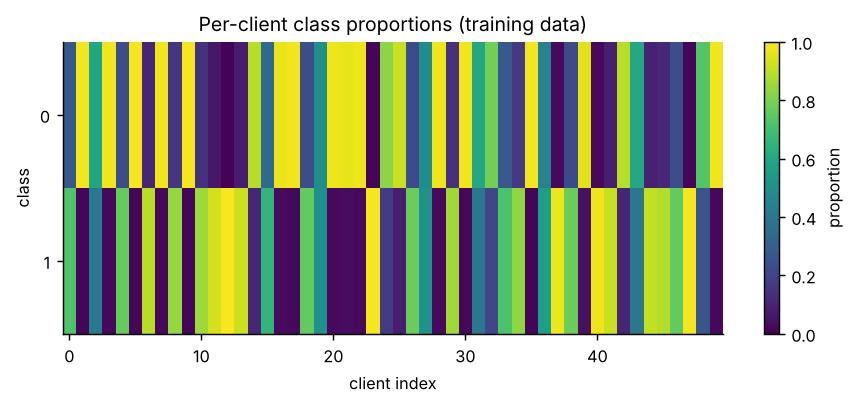

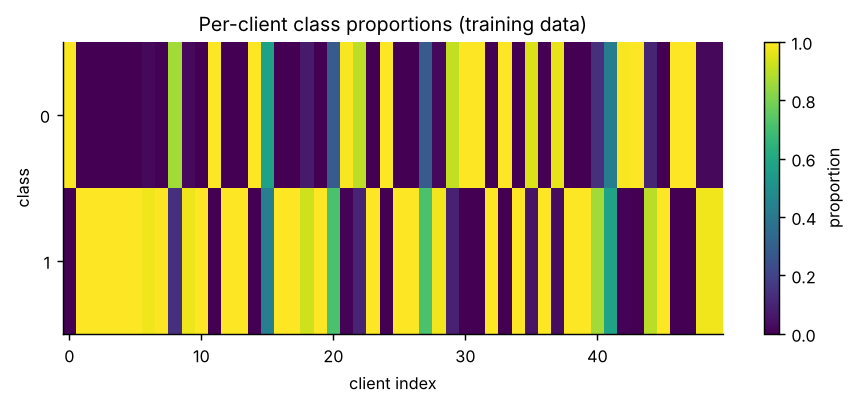

In [4]:
from IPython.display import Image, display
for f in ['scenario_label_skew_label-heatmap','partition_dirichlet_alpha_0_1_label-heatmap']:
    display(Image(f'../reports/figures/data-profiling/{f}.png', width=640))

*Top: client label proportions under label skew. Bottom: Dirichlet(α=0.1) partition – most clients hold almost a single class.*